In [1]:
# This is Lecture08 - Demo
# of the "Data Science" class at Technische Hochschule Rosenheim

# Demo- Train/Test Split and Fitting Graph

It is easy to split data into training and testing sets using sklearn. We use a simple loop for fitting the model for different values of leaf nodes, and matplotlib to draw a fitting graph.

In [2]:
%matplotlib inline
import numpy as np
from pandas import Series, DataFrame
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split

In [3]:
# read and prepare the data
iris = pd.read_csv('data/iris_clean.csv', index_col=0)
X = iris[['sepal length','sepal width', 'petal length', 'petal width']]
y = iris['class']

In [4]:
# shuffle data and split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 1)

In [5]:
## Use the holdout method to evaluate the decision tree classifiers with default parameters
classifier = DecisionTreeClassifier()
name = "Decision Tree"
classifier.fit(X_train, y_train)
score_train = classifier.score(X_train, y_train)
score_test  = classifier.score(X_test, y_test)
print('%20s has a score of %1.3f on the training data and %1.3f on the test data' %
      (name, score_train, score_test))

       Decision Tree has a score of 1.000 on the training data and 0.933 on the test data


**Interpretation:** This looks like overfitting - the accuracy score on the testing-set is considerably lower than on the training-set (and the score of 1.000 on the training set is very suspicous anyway!).

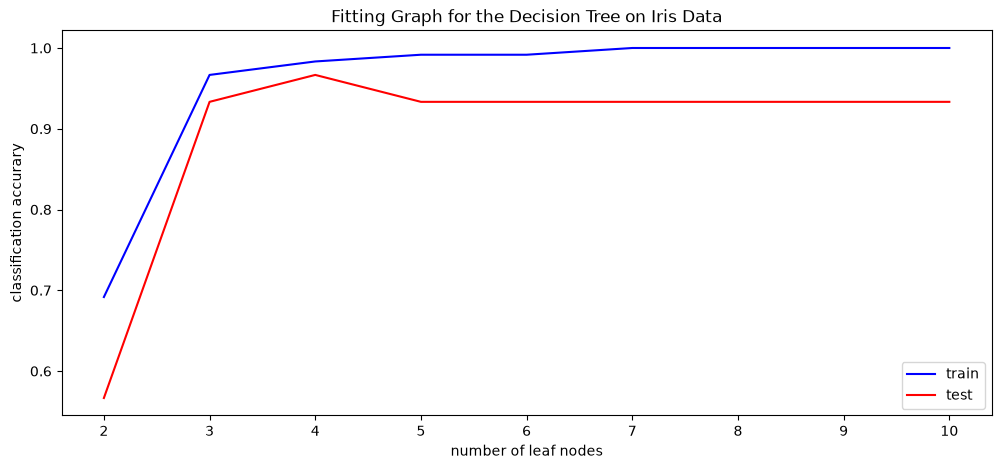

In [6]:
## Generate fitting graph for Decision Tree

mlfs = range(2, 11) # evaluate between 2 and 10 leaf nodes
dt_score_train = []
dt_score_test = []
for mlf in mlfs:
    dtc = DecisionTreeClassifier(max_leaf_nodes=mlf)
    dtc.fit(X_train, y_train)
    dt_score_train.append(dtc.score(X_train, y_train))
    dt_score_test.append(dtc.score(X_test, y_test))

figure = plt.figure(figsize=(12, 5))
ax = plt.subplot(1, 1, 1)
ax.set_title('Fitting Graph for the Decision Tree on Iris Data')
ax.plot(mlfs, dt_score_train, c='blue', label='train')
ax.plot(mlfs, dt_score_test, c='red', label='test')
ax.legend(loc='lower right')
plt.xlabel('number of leaf nodes')
plt.ylabel('classification accurary');

**Interpretation**: This is a typical fitting graph - the score on the training-set improves with increasing number of leaf nodes. The performance on the testing-set reaches a maximum at 4 leaf nodes and decreases after this. So this decision tree classifier is overfitting with 5 or more leaf nodes.

----